In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive, files
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [5]:
drive.mount("/content/drive")
CARPETA_DRIVE = Path("/content/drive/MyDrive/ModelLOA/Datos_Procesados")
ARCHIVO_DATOS = CARPETA_DRIVE / "dataset_homicidios_final.csv"

df_homicidios = pd.read_csv(
    ARCHIVO_DATOS,
    engine="python",
    sep=None,
    encoding="utf-8-sig",
)

Mounted at /content/drive


In [6]:
df_homicidios

,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado,anio,mes,dia_semana_num,dia_semana,categoria_incidencia
0,1,01D01,01/01/2014,madrugada,1,Año Nuevo,1,2014,1,2,Miercoles,media
1,1,01D01,01/01/2014,manana,0,Año Nuevo,1,2014,1,2,Miercoles,baja
2,1,01D01,01/01/2014,noche,0,Año Nuevo,1,2014,1,2,Miercoles,baja
3,1,01D01,01/01/2014,tarde,0,Año Nuevo,1,2014,1,2,Miercoles,baja
4,1,01D01,02/01/2014,madrugada,0,NO_FERIADO,0,2014,1,3,Jueves,baja
...,...,...,...,...,...,...,...,...,...,...,...,...
2590555,24,24D02,30/08/2026,tarde,0,NO_FERIADO,0,2026,8,6,Domingo,baja
2590556,24,24D02,31/08/2026,madrugada,0,NO_FERIADO,0,2026,8,0,Lunes,baja
2590557,24,24D02,31/08/2026,manana,0,NO_FERIADO,0,2026,8,0,Lunes,baja
2590558,24,24D02,31/08/2026,noche,3,NO_FERIADO,0,2026,8,0,Lunes,alta


In [7]:
# Convertir fecha
df_homicidios["fecha"] = pd.to_datetime(df_homicidios["fecha"], dayfirst=True)

# Variables predictoras
columnas = [
    "codigo_provincia",
    "codigo_distrito",
    "franja_horaria",
    "es_feriado",
    "anio",
    "mes",
    "dia_semana_num"
]

X = df_homicidios[columnas]
y = df_homicidios["categoria_incidencia"]

In [8]:
# One-Hot Encoding para variables categóricas
X = pd.get_dummies(
    X,
    columns=[
        "codigo_distrito",
        "franja_horaria"
    ],
    dtype=int
)

X.head()

,codigo_provincia,es_feriado,anio,mes,dia_semana_num,codigo_distrito_01D01,codigo_distrito_01D02,codigo_distrito_01D03,codigo_distrito_01D04,codigo_distrito_01D05,...,codigo_distrito_22D03,codigo_distrito_23D01,codigo_distrito_23D02,codigo_distrito_23D03,codigo_distrito_24D01,codigo_distrito_24D02,franja_horaria_madrugada,franja_horaria_manana,franja_horaria_noche,franja_horaria_tarde
0,1,1,2014,1,2,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,1,1,2014,1,2,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,1,1,2014,1,2,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
3,1,1,2014,1,2,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,1,0,2014,1,3,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [9]:
# Fecha de corte (80% de las fechas)
fecha_corte = df_homicidios["fecha"].quantile(0.80)

# Separar entrenamiento y prueba
train_mask = df_homicidios["fecha"] < fecha_corte
test_mask = df_homicidios["fecha"] >= fecha_corte

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Fecha de corte:", fecha_corte)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Fecha de corte: 2024-02-18 00:00:00
Entrenamiento: (2072000, 149)
Prueba: (518560, 149)


In [10]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Definir el modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Entrenar el modelo
modelo_rf.fit(X_train, y_train)

# Obtener las probabilidades de predicción para el conjunto de prueba
y_proba = modelo_rf.predict_proba(X_test)
print("Clases del modelo:", modelo_rf.classes_)

Clases del modelo: ['alta' 'baja' 'media']


### Optimización de Umbral para Maximizar el Recall de las Clases Críticas ('alta' y 'media')
Por defecto, el modelo asigna la clase con mayor probabilidad (umbral de 0.5 en binario o el máximo en multiclase). Al modificar el umbral de decisión para las clases minoritarias, podemos aumentar drásticamente su Recall (sensibilidad).

In [11]:
# Mapear índices de clases
classes = list(modelo_rf.classes_)
idx_alta = classes.index("alta")
idx_media = classes.index("media")
idx_baja = classes.index("baja")

# Evaluamos diferentes umbrales para la clase 'alta' y 'media' para ver cómo afecta al Recall
umbrales = np.arange(0.05, 0.5, 0.05)
resultados_umbrales = []

for u in umbrales:
    # Si la probabilidad de 'alta' supera el umbral 'u', predecimos 'alta'.
    # Si no, si la de 'media' supera 'u', predecimos 'media'. De lo contrario, 'baja'.
    preds_personalizadas = []
    for prob in y_proba:
        if prob[idx_alta] >= u:
            preds_personalizadas.append("alta")
        elif prob[idx_media] >= u:
            preds_personalizadas.append("media")
        else:
            preds_personalizadas.append("baja")

    preds_personalizadas = np.array(preds_personalizadas)

    # Calcular reporte
    reporte = classification_report(y_test, preds_personalizadas, output_dict=True, zero_division=0)

    resultados_umbrales.append({
        "Umbral": u,
        "Recall Alta": reporte["alta"]["recall"],
        "Precision Alta": reporte["alta"]["precision"],
        "Recall Media": reporte["media"]["recall"],
        "F1-Score Global (weighted)": reporte["weighted avg"]["f1-score"]
    })

df_umbrales = pd.DataFrame(resultados_umbrales)
display(df_umbrales)

,Umbral,Recall Alta,Precision Alta,Recall Media,F1-Score Global (weighted)
0,0.05,1.000000,0.006576,0.000000,0.000086
1,0.10,1.000000,0.006576,0.000000,0.000086
2,0.15,1.000000,0.006576,0.000000,0.000086
3,0.20,0.998827,0.006892,0.002554,0.000132
4,0.25,0.992082,0.007640,0.012131,0.114450
5,0.30,0.970088,0.009003,0.031923,0.333049
6,0.35,0.913783,0.009755,0.093935,0.440293
7,0.40,0.826979,0.012334,0.060894,0.686674
8,0.45,0.673900,0.016759,0.025698,0.820799


### Visualización del impacto del Umbral en el Recall

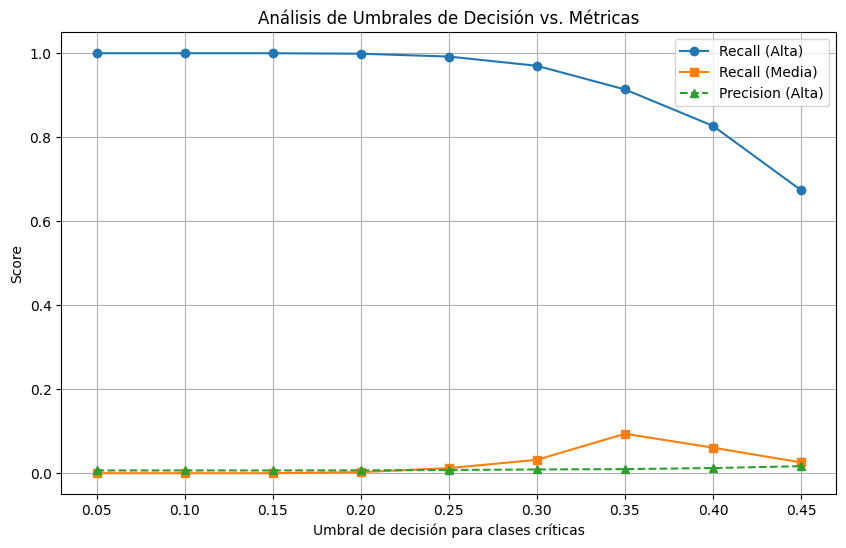

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(df_umbrales["Umbral"], df_umbrales["Recall Alta"], marker='o', label='Recall (Alta)')
plt.plot(df_umbrales["Umbral"], df_umbrales["Recall Media"], marker='s', label='Recall (Media)')
plt.plot(df_umbrales["Umbral"], df_umbrales["Precision Alta"], marker='^', label='Precision (Alta)', linestyle='--')

plt.title("Análisis de Umbrales de Decisión vs. Métricas")
plt.xlabel("Umbral de decisión para clases críticas")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

--- METRICAS DE MATRIZ DE CONFUSION (Umbral: 0.35) ---

Clase: 'ALTA'
  - Verdaderos Positivos (TP): 3116
  - Falsos Positivos (FP):     316323
  - Verdaderos Negativos (TN): 198827
  - Falsos Negativos (FN):     294
----------------------------------------
Clase: 'MEDIA'
  - Verdaderos Positivos (TP): 1177
  - Falsos Positivos (FP):     49997
  - Verdaderos Negativos (TN): 456033
  - Falsos Negativos (FN):     11353
----------------------------------------
Clase: 'BAJA'
  - Verdaderos Positivos (TP): 147420
  - Falsos Positivos (FP):     527
  - Verdaderos Negativos (TN): 15413
  - Falsos Negativos (FN):     355200
----------------------------------------


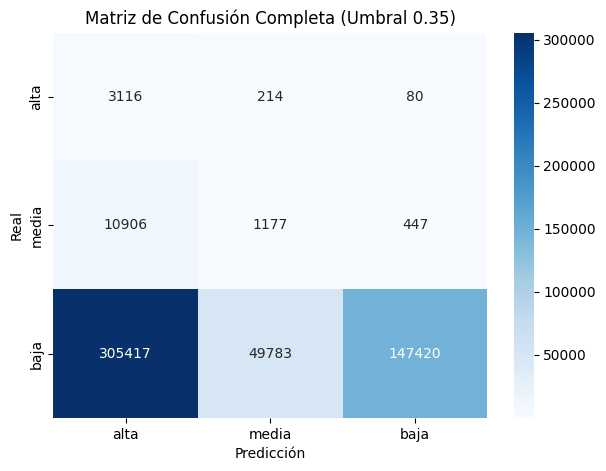

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Definir el umbral óptimo seleccionado
umbral_optimo = 0.35

# Aplicar el umbral óptimo en las probabilidades predichas
preds_optimas = []
for prob in y_proba:
    if prob[idx_alta] >= umbral_optimo:
        preds_optimas.append("alta")
    elif prob[idx_media] >= umbral_optimo:
        preds_optimas.append("media")
    else:
        preds_optimas.append("baja")

preds_optimas = np.array(preds_optimas)

# 1. Calcular la Matriz de Confusión Multiclase
labels = ["alta", "media", "baja"]
cm = confusion_matrix(y_test, preds_optimas, labels=labels)

# 2. Desglosar TP, FP, TN, FN para cada clase de forma Uno-Contra-Todos (One-vs-All)
print(f"--- METRICAS DE MATRIZ DE CONFUSION (Umbral: {umbral_optimo}) ---\n")
for i, clase in enumerate(labels):
    tp = cm[i, i]
    fn = sum(cm[i, :]) - tp
    fp = sum(cm[:, i]) - tp
    tn = sum(sum(cm)) - tp - fn - fp

    print(f"Clase: '{clase.upper()}'")
    print(f"  - Verdaderos Positivos (TP): {tp}")
    print(f"  - Falsos Positivos (FP):     {fp}")
    print(f"  - Verdaderos Negativos (TN): {tn}")
    print(f"  - Falsos Negativos (FN):     {fn}")
    print("-" * 40)

# Graficar la matriz de confusión visualmente
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Matriz de Confusión Completa (Umbral {umbral_optimo})")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

/tmp/ipykernel_769/1679320138.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importancias_top15, x="Importancia", y="Variable", palette="viridis")


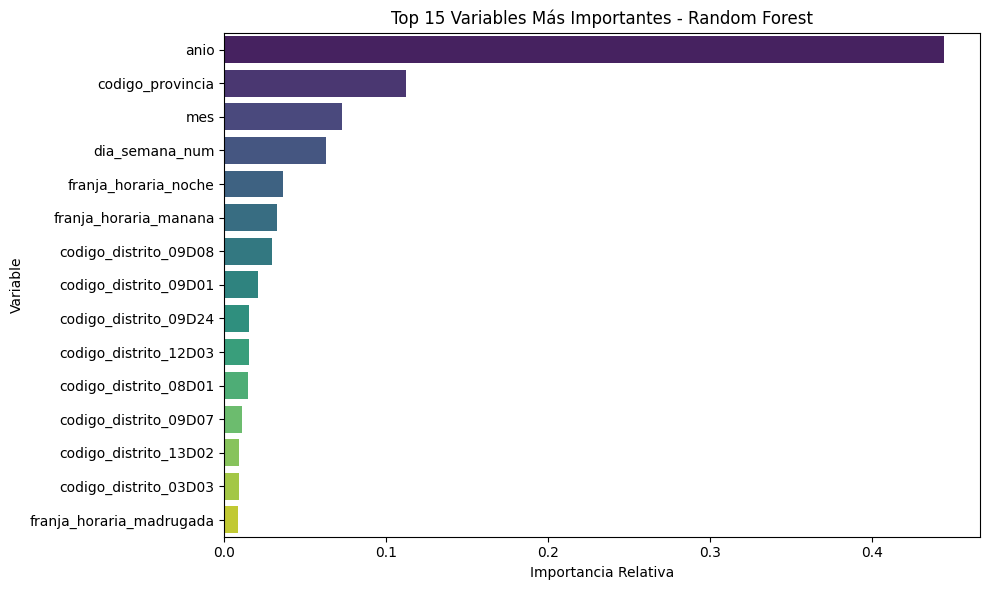

In [14]:
# 3. Extraer y Graficar las Top 15 Variables más Importantes
importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": modelo_rf.feature_importances_
})

importancias_top15 = importancias.sort_values(by="Importancia", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=importancias_top15, x="Importancia", y="Variable", palette="viridis")
plt.title("Top 15 Variables Más Importantes - Random Forest")
plt.xlabel("Importancia Relativa")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()